<a href="https://colab.research.google.com/github/Dharini-123/-Plant-Disease-Classification/blob/main/Plant_Disease_Logistic_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

In [4]:
from google.colab import files

uploaded = files.upload()

df = pd.read_csv('plant_disease_dataset.csv')

print("Dataset Loaded Successfully!")
print(df.head())

Saving plant_disease_dataset.csv to plant_disease_dataset.csv
Dataset Loaded Successfully!
   temperature   humidity   rainfall   soil_pH  disease_present
0    27.483571  33.215053   0.572758  4.975875                1
1    24.308678  36.945005  42.522346  8.165266                0
2    28.238443  34.026189  16.095303  6.316734                1
3    32.615149  41.104180  20.311015  6.164949                0
4    23.829233  51.971785  11.851323  8.482468                0


In [5]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDisease Distribution:")
print(df['disease_present'].value_counts())

Dataset Shape: (10000, 5)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   temperature      10000 non-null  float64
 1   humidity         10000 non-null  float64
 2   rainfall         10000 non-null  float64
 3   soil_pH          10000 non-null  float64
 4   disease_present  10000 non-null  int64  
dtypes: float64(4), int64(1)
memory usage: 390.8 KB
None

Missing Values:
temperature        0
humidity           0
rainfall           0
soil_pH            0
disease_present    0
dtype: int64

Disease Distribution:
disease_present
0    7590
1    2410
Name: count, dtype: int64


In [6]:
X = df[['temperature',
        'humidity',
        'rainfall',
        'soil_pH']]

y = df['disease_present']

print("Input Features:", X.shape)
print("Target Variable:", y.shape)

Input Features: (10000, 4)
Target Variable: (10000,)


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (8000, 4)
Testing Data: (2000, 4)


In [8]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = LogisticRegression(max_iter=1000)

model.fit(X_train_scaled, y_train)

print("Logistic Regression Model Trained Successfully!")

Logistic Regression Model Trained Successfully!


In [9]:
y_pred = model.predict(X_test_scaled)

print("Actual Values:", y_test.values[:10])
print("Predicted Values:", y_pred[:10])

Actual Values: [0 1 0 0 0 0 0 0 1 0]
Predicted Values: [0 0 0 0 0 0 0 0 0 0]


In [10]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

y_prob = model.predict_proba(X_test_scaled)[:, 1]

auc = roc_auc_score(y_test, y_prob)

print("Logistic Regression Performance")
print("--------------------------------")
print("Accuracy  :", round(accuracy * 100, 2), "%")
print("Precision :", round(precision, 4))
print("Recall    :", round(recall, 4))
print("F1 Score  :", round(f1, 4))
print("ROC-AUC   :", round(auc, 4))

Logistic Regression Performance
--------------------------------
Accuracy  : 77.45 %
Precision : 0.6703
Recall    : 0.1266
F1 Score  : 0.2129
ROC-AUC   : 0.7127


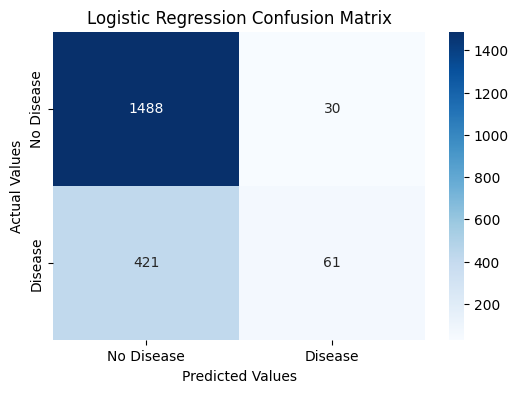

In [11]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Disease', 'Disease'],
    yticklabels=['No Disease', 'Disease']
)

plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.title("Logistic Regression Confusion Matrix")

plt.show()

In [12]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.78      0.98      0.87      1518
           1       0.67      0.13      0.21       482

    accuracy                           0.77      2000
   macro avg       0.72      0.55      0.54      2000
weighted avg       0.75      0.77      0.71      2000



In [13]:
new_data = pd.DataFrame({
    'temperature': [30],
    'humidity': [75],
    'rainfall': [40],
    'soil_pH': [6.5]
})

new_data_scaled = scaler.transform(new_data)

prediction = model.predict(new_data_scaled)

probability = model.predict_proba(new_data_scaled)

if prediction[0] == 1:
    print("Disease Detected")
else:
    print("No Disease Detected")

print("Disease Probability:",
      round(probability[0][1] * 100, 2), "%")

Disease Detected
Disease Probability: 59.68 %


In [14]:
balanced_model = LogisticRegression(
    max_iter=1000,
    class_weight='balanced'
)

balanced_model.fit(X_train_scaled, y_train)

balanced_pred = balanced_model.predict(X_test_scaled)

print("Balanced Model Accuracy:",
      accuracy_score(y_test, balanced_pred))

print("Balanced Model Recall:",
      recall_score(y_test, balanced_pred))

print("Balanced Model F1 Score:",
      f1_score(y_test, balanced_pred))

print(confusion_matrix(y_test, balanced_pred))

Balanced Model Accuracy: 0.6465
Balanced Model Recall: 0.6784232365145229
Balanced Model F1 Score: 0.4805290227773696
[[966 552]
 [155 327]]
